# import modules

In [1]:
from groq import Groq
from dotenv import load_dotenv
import os

# Load environment variables from .env file
load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY not found in environment variables")

# Initialize Groq client
client = Groq(api_key=os.getenv("GROQ_API_KEY"))

print("Setup complete! Groq client initialized.")

Setup complete! Groq client initialized.


 Extra information 

 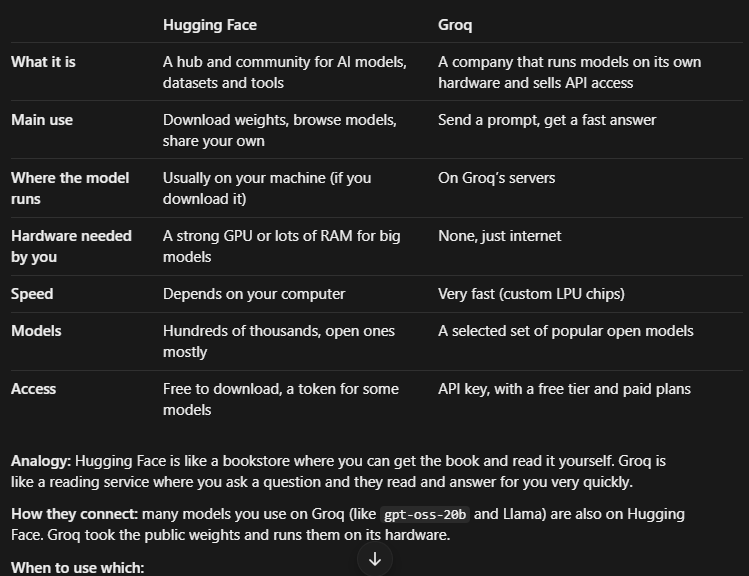

# set up the LLM


In [ ]:
total_tokens_used = 0
input_tokens = 0
output_tokens = 0

def llm_call(prompt):
    """
    Simple wrapper for Groq API calls.

    Args:
        prompt (str): The prompt to send to the LLM

    Returns:
        str: The LLM's response text
    """
    global total_tokens_used, input_tokens, output_tokens

    # client is the instance of Groq created in the setup cell
    response = client.chat.completions.create(
        # gpt-oss-20b is an open-weight model: its weights are on Hugging Face, Groq just runs it.
        # It is a reasoning model: it writes its "thinking" first, then the answer,
        # and both use tokens from the same output limit.
        model="openai/gpt-oss-20b",
        messages=[{"role": "user", "content": prompt}],
        # Less thinking means faster answers and fewer tokens used.
        reasoning_effort="low",
        # Caps OUTPUT only: answer tokens + reasoning tokens <= 4096.
        # Prompt (input) tokens do not count toward this limit.
        max_completion_tokens=4096,
    )

    # Running totals across all calls
    usage = response.usage                          # token counts for THIS call
    input_tokens += usage.prompt_tokens             # tokens sent to the model (running total)
    output_tokens += usage.completion_tokens        # tokens the model produced, thinking + answer (running total)
    total_tokens_used += usage.total_tokens         # input + output for this call (running total)
    print(f"[this call: in={usage.prompt_tokens}, out={usage.completion_tokens}, total={usage.total_tokens}]")

    return response.choices[0].message.content

# try the model 

In [18]:
test_response = llm_call("Say 'Hello, World!' in a creative way.")
print("Test response:", test_response)

[tokens this call: 291]
Test response: 🌟 **Behold!** 🌟

> **H**ave you ever wondered what the universe says when it greets a brand‑new day?  
>  
>  **E**xploding in colors, it shouts,  
>  
>  **L**ightning‑fast syllables,  
>  
>  **L**acing the cosmos with wonder,  
>  
>  **O**nly the bold hear its pulse.  
>  
>  **W**aves of stardust ripple through the void,  
>  
>  **O**verheads swirl like galaxies in a dance.  
>  
>  **R**eaching out, the cosmos beckons,  
>  
>  **L**aughter bubbles in every corner,  
>  
>  **D**rawing smiles across the night sky.  
>  
>  **!**  

**Hello, World!** 🌌🚀


# Implement an llm chain call

In [24]:
def writing_improvement_chain(topic):
    """
    A three-step chain that generates, critiques, and improves writing.

    Args:
        topic (str): The topic to write about

    Returns:
        dict: Contains 'draft', 'critique', and 'final' versions
    """
    print(f"Starting writing improvement chain for topic: '{topic}'\n")
    print("=" * 70)

    # Step 1: Generate first draft
    print("\nSTEP 1: Generating initial draft...")
    draft = llm_call(f"Write a paragraph about {topic}")
    print(f"\nDraft:\n{draft}")

    # Step 2: Critique the draft
    print("\n" + "=" * 70)
    print("\nSTEP 2: Analyzing draft for improvements...")
    critique = llm_call(f"What could be improved in this paragraph? Be specific. Do not rewrite the content, only output 3 improvements.\n\n{draft}")
    print(f"\nCritique:\n{critique}")

    # Step 3: Rewrite with improvements
    print("\n" + "=" * 70)
    print("\nSTEP 3: Rewriting with improvements...")
    final = llm_call(f"Rewrite this paragraph, keep it the same size as original and incorporate the following feedback:\n\nOriginal:\n{draft}\n\nFeedback:\n{critique}")
    print(f"\nFinal Version:\n{final}")

    print("\n" + "=" * 70)
    print("\nChain complete!\n")

    return {
        "draft": draft,
        "critique": critique,
        "final": final
    }

print("writing_improvement_chain() function defined successfully!")

writing_improvement_chain() function defined successfully!


# example 

In [25]:
result = writing_improvement_chain("artificial intelligence")

Starting writing improvement chain for topic: 'artificial intelligence'


STEP 1: Generating initial draft...
[this call: in=77, out=161, total=238]

Draft:
Artificial intelligence (AI) is a branch of computer science that focuses on creating systems capable of performing tasks that normally require human intelligence. By harnessing algorithms, vast datasets, and powerful hardware, AI models can learn to recognize patterns, understand language, make predictions, and even generate creative content. From self‑driving cars and personalized recommendation engines to sophisticated medical diagnostics and intelligent virtual assistants, AI is transforming industries, driving economic growth, and raising important ethical questions about privacy, bias, and the future of work. As research continues to push the boundaries of what machines can perceive and reason about, AI promises to reshape how we interact with technology and each other, while also demanding careful stewardship to ensure its b